In [53]:
# Supply-Chain Late-Delivery Risk Model
## Problem framing
##- **Who has the problem:** The logistics and operations team of a global distributor that ships orders across many markets using different shipping modes. Late deliveries hurt customer satisfaction and cost the company money.
##- **Decision the model supports:** Before an order ships, the team decides whether to upgrade its shipping mode or warn the customer in advance. The model scores each order's risk of being late using only information known at that moment.
##- **Target variable:** Late_delivery_risk (1 = late, 0 = on time)
##- **Metric that matters and why:** Recall for the late class is the main metric. Missing a late order (a false negative) means an unhappy customer and no chance to act, while a false alarm only costs a possible unnecessary upgrade or warning. Precision, F1 and ROC-AUC are reported alongside it so we can see how many false alarms we accept to catch more late orders. Accuracy alone would be misleading, so it is not the main metric.

In [54]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
import pandas as pd, sklearn, streamlit
print(pd.__version__, sklearn.__version__)

3.1.1 1.9.1


In [56]:
import os
print(os.listdir("data"))

['DataCoSupplyChainDataset.csv', 'DescriptionDataCoSupplyChain.csv']


In [57]:
import pandas as pd

df = pd.read_csv("data/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(df.shape)
df.head()

(180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2/3/2018 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/15/2018 11:24,Standard Class


In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 53 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Id                    180519 non-null  int64  
 8   Category Name                  180519 non-null  str    
 9   Customer City                  180519 non-null  str    
 10  Customer Country               180519 non-null  str    
 11  Customer Email                 180519 non-null  str    
 12  Customer Fname                 180519 non

In [59]:
df["Late_delivery_risk"].value_counts(normalize=True)

Late_delivery_risk
1    0.548291
0    0.451709
Name: proportion, dtype: float64

In [60]:
list(df.columns)

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country',
 'Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product P

In [61]:
list(df.columns[:27])

['Type',
 'Days for shipping (real)',
 'Days for shipment (scheduled)',
 'Benefit per order',
 'Sales per customer',
 'Delivery Status',
 'Late_delivery_risk',
 'Category Id',
 'Category Name',
 'Customer City',
 'Customer Country',
 'Customer Email',
 'Customer Fname',
 'Customer Id',
 'Customer Lname',
 'Customer Password',
 'Customer Segment',
 'Customer State',
 'Customer Street',
 'Customer Zipcode',
 'Department Id',
 'Department Name',
 'Latitude',
 'Longitude',
 'Market',
 'Order City',
 'Order Country']

In [62]:
list(df.columns[27:])

['Order Customer Id',
 'order date (DateOrders)',
 'Order Id',
 'Order Item Cardprod Id',
 'Order Item Discount',
 'Order Item Discount Rate',
 'Order Item Id',
 'Order Item Product Price',
 'Order Item Profit Ratio',
 'Order Item Quantity',
 'Sales',
 'Order Item Total',
 'Order Profit Per Order',
 'Order Region',
 'Order State',
 'Order Status',
 'Order Zipcode',
 'Product Card Id',
 'Product Category Id',
 'Product Description',
 'Product Image',
 'Product Name',
 'Product Price',
 'Product Status',
 'shipping date (DateOrders)',
 'Shipping Mode']

In [63]:
pd.crosstab(df["Delivery Status"], df["Late_delivery_risk"])

Late_delivery_risk,0,1
Delivery Status,,
Advance shipping,41592,0
Late delivery,0,98977
Shipping canceled,7754,0
Shipping on time,32196,0


In [64]:
df.isna().sum()[lambda s: s > 0]

Customer Lname              8
Customer Zipcode            3
Order Zipcode          155679
Product Description    180519
dtype: int64

In [65]:
gap = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
pd.crosstab(gap > 0, df["Late_delivery_risk"])

Late_delivery_risk,0,1
row_0,,
False,77119,0
True,4423,98977


In [66]:
order_d = pd.to_datetime(df["order date (DateOrders)"])
ship_d = pd.to_datetime(df["shipping date (DateOrders)"])
print(((ship_d - order_d).dt.days == df["Days for shipping (real)"]).mean())

0.9742021615453221


In [67]:
print(df["Order Id"].nunique(), len(df))
print(df["Product Status"].nunique())
print(df["Order Status"].value_counts())

65752 180519
1
Order Status
COMPLETE           59491
PENDING_PAYMENT    39832
PROCESSING         21902
PENDING            20227
CLOSED             19616
ON_HOLD             9804
SUSPECTED_FRAUD     4062
CANCELED            3692
PAYMENT_REVIEW      1893
Name: count, dtype: int64


In [68]:
print((df.groupby("Order Id")["Late_delivery_risk"].nunique() > 1).sum())

0


In [69]:
# date features (row-wise, so no leakage)
df["order_dt"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_month"] = df["order_dt"].dt.month
df["order_weekday"] = df["order_dt"].dt.weekday
df["order_hour"] = df["order_dt"].dt.hour

leak_cols = ["Days for shipping (real)", "Delivery Status",
             "Order Status", "shipping date (DateOrders)"]
id_pii_cols = ["Customer Email", "Customer Fname", "Customer Lname",
               "Customer Password", "Customer Street", "Customer Zipcode",
               "Customer Id", "Order Customer Id", "Order Item Id",
               "Order Item Cardprod Id", "Category Id", "Department Id",
               "Product Card Id", "Product Category Id"]
useless_cols = ["Product Description", "Order Zipcode",
                "Product Image", "Product Status"]
profit_cols = ["Benefit per order", "Order Profit Per Order",
               "Order Item Profit Ratio", "Sales per customer"]  # saved for the stretch profit model

y = df["Late_delivery_risk"]
groups = df["Order Id"]

drop_cols = (leak_cols + id_pii_cols + useless_cols + profit_cols +
             ["Late_delivery_risk", "Order Id", "order date (DateOrders)", "order_dt"])
X = df.drop(columns=drop_cols)

print(X.shape)
print(list(X.columns))

KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(len(X_train), len(X_test))
print(y_train.mean(), y_test.mean())
print(len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))  # must be 0

144650 35869
0.5482751469063256 0.5483565195572778
0


In [ ]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print(X_train[cat_cols].nunique().sort_values(ascending=False))

Order City          3510
Order State         1074
Customer City        563
Order Country        160
Product Name         118
Category Name         50
Customer State        46
Order Region          23
Department Name       11
Market                 5
Type                   4
Shipping Mode          4
Customer Segment       3
Customer Country       2
dtype: int64


In [ ]:
print((X_train["Order Item Product Price"] == X_train["Product Price"]).mean())
print(X_train[["Sales", "Order Item Total", "Order Item Product Price",
               "Product Price", "Order Item Discount"]].corr().round(2))

1.0
                          Sales  Order Item Total  Order Item Product Price  \
Sales                      1.00              0.99                      0.79   
Order Item Total           0.99              1.00                      0.78   
Order Item Product Price   0.79              0.78                      1.00   
Product Price              0.79              0.78                      1.00   
Order Item Discount        0.62              0.50                      0.49   

                          Product Price  Order Item Discount  
Sales                              0.79                 0.62  
Order Item Total                   0.78                 0.50  
Order Item Product Price           1.00                 0.49  
Product Price                      1.00                 0.49  
Order Item Discount                0.49                 1.00  


In [ ]:
redundant = ["Order Item Product Price", "Order Item Total"]
geo_cols = ["Order City", "Order State", "Customer City"]

X_train = X_train.drop(columns=redundant + geo_cols)
X_test = X_test.drop(columns=redundant + geo_cols)

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print(X_train.shape, X_test.shape)
print("numeric:", num_cols)
print("categorical:", cat_cols)

(144650, 22) (35869, 22)
numeric: ['Days for shipment (scheduled)', 'Latitude', 'Longitude', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Quantity', 'Sales', 'Product Price', 'order_month', 'order_weekday', 'order_hour']
categorical: ['Type', 'Category Name', 'Customer Country', 'Customer Segment', 'Customer State', 'Department Name', 'Market', 'Order Country', 'Order Region', 'Product Name', 'Shipping Mode']


In [ ]:
eda = X_train.copy()
eda["late"] = y_train

for col in ["Shipping Mode", "Market", "Type", "Customer Segment",
            "Days for shipment (scheduled)"]:
    print(eda.groupby(col)["late"].agg(["mean", "count"]).round(3), "\n")

                 mean  count
Shipping Mode               
First Class     0.953  22229
Same Day        0.465   7767
Second Class    0.768  28202
Standard Class  0.380  86452 

               mean  count
Market                    
Africa        0.546   9175
Europe        0.552  40338
LATAM         0.539  41480
Pacific Asia  0.554  33021
USCA          0.552  20636 

           mean  count
Type                  
CASH      0.572  15681
DEBIT     0.570  55405
PAYMENT   0.573  33768
TRANSFER  0.487  39796 

                   mean  count
Customer Segment              
Consumer          0.547  74630
Corporate         0.547  44193
Home Office       0.553  25827 

                                mean  count
Days for shipment (scheduled)              
0                              0.465   7767
1                              0.953  22229
2                              0.768  28202
4                              0.380  86452 



In [ ]:
print(pd.crosstab(X_train["Shipping Mode"], X_train["Days for shipment (scheduled)"]))

Days for shipment (scheduled)     0      1      2      4
Shipping Mode                                           
First Class                       0  22229      0      0
Same Day                       7767      0      0      0
Second Class                      0      0  28202      0
Standard Class                    0      0      0  86452


In [ ]:
print(eda.groupby("Customer Segment")["late"].agg(["mean", "count"]).round(3))
print(eda.groupby("Days for shipment (scheduled)")["late"].agg(["mean", "count"]).round(3))

                   mean  count
Customer Segment              
Consumer          0.547  74630
Corporate         0.547  44193
Home Office       0.553  25827
                                mean  count
Days for shipment (scheduled)              
0                              0.465   7767
1                              0.953  22229
2                              0.768  28202
4                              0.380  86452


In [ ]:
rate = eda.groupby("Shipping Mode")["late"].mean()
rule = (X_train["Shipping Mode"].map(rate) > 0.5).astype(int)
print("accuracy of mode-only rule:", (rule == y_train).mean().round(3))

accuracy of mode-only rule: 0.696


In [ ]:
import matplotlib.pyplot as plt

eda.groupby("Shipping Mode")["late"].mean().sort_values().plot(kind="barh")
plt.xlabel("Late rate")
plt.title("Late rate by shipping mode (train set)")
plt.show()

C:\Users\NOUREEN\AppData\Local\Temp\ipykernel_22532\1116072232.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


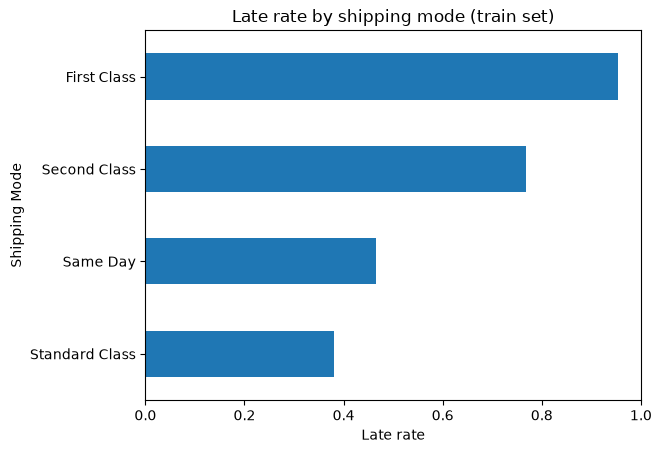

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt

eda.groupby("Shipping Mode")["late"].mean().sort_values().plot(kind="barh")
plt.xlabel("Late rate")
plt.title("Late rate by shipping mode (train set)")
plt.show()

In [ ]:
X_train = X_train.drop(columns=["Days for shipment (scheduled)"])
X_test = X_test.drop(columns=["Days for shipment (scheduled)"])

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print(X_train.shape)

(144650, 21)


In [ ]:
real = df.loc[X_train.index, "Days for shipping (real)"]
sched = df.loc[X_train.index, "Days for shipment (scheduled)"]
print(pd.DataFrame({"mode": X_train["Shipping Mode"], "scheduled": sched, "real": real})
      .groupby("mode")[["scheduled", "real"]].mean().round(2))

                scheduled  real
mode                           
First Class           1.0  2.00
Same Day              0.0  0.49
Second Class          2.0  3.99
Standard Class        4.0  3.99


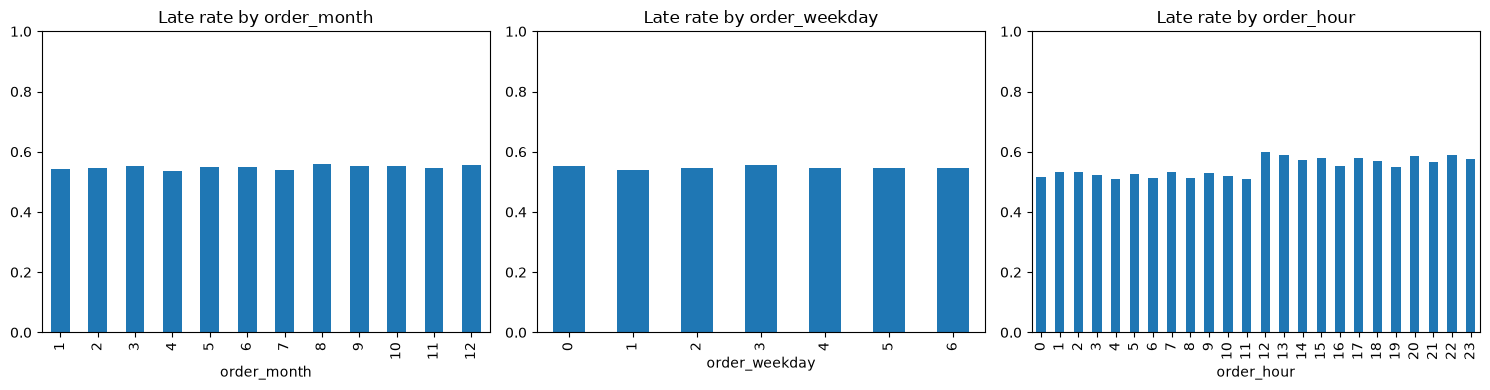

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["order_month", "order_weekday", "order_hour"]):
    eda.groupby(col)["late"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Late rate by {col}")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
print(eda[num_cols + ["late"]].corr()["late"].sort_values())

Sales                      -0.004406
Product Price              -0.003959
Order Item Discount        -0.001608
order_weekday              -0.001444
Longitude                  -0.000759
Order Item Quantity         0.001029
Order Item Discount Rate    0.001061
Latitude                    0.001357
order_month                 0.006410
order_hour                  0.044784
late                        1.000000
Name: late, dtype: float64


In [ ]:
print(eda[num_cols + ["late"]].corr()["late"].sort_values())

Sales                      -0.004406
Product Price              -0.003959
Order Item Discount        -0.001608
order_weekday              -0.001444
Longitude                  -0.000759
Order Item Quantity         0.001029
Order Item Discount Rate    0.001061
Latitude                    0.001357
order_month                 0.006410
order_hour                  0.044784
late                        1.000000
Name: late, dtype: float64


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_train, rule))

              precision    recall  f1-score   support

           0       0.61      0.88      0.72     65342
           1       0.85      0.54      0.66     79308

    accuracy                           0.70    144650
   macro avg       0.73      0.71      0.69    144650
weighted avg       0.74      0.70      0.69    144650



In [ ]:
## EDA insights (training set only)
#1. **Shipping mode is by far the strongest signal.** The late rate is 95.3% for First Class, 76.8% for Second Class, 46.5% for Same Day and 38.0% for Standard Class. Scheduled days map one-to-one to the mode, so only the mode is kept.
#2. **Faster modes are late mostly because of unrealistic promises.** Average actual shipping time is 2.0 days for First Class (promised 1), 3.99 for Second Class (promised 2) and 3.99 for Standard (promised 4). Second Class is no faster than Standard in practice. *(Hypothesis from averages; real days are used for analysis only, never as a feature.)*
#3. **Market, customer segment, month and weekday carry almost no signal.** Late rates stay between about 0.54 and 0.56 across their values.
#4. **Order hour has a small effect:** orders placed after noon are slightly more often late.
#5. **A rule using only shipping mode is a strong baseline:** 0.696 accuracy, but only 0.54 recall for late orders. Our models must improve recall without destroying precision.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                           min_frequency=100))]), cat_cols),
])

groups_train = groups.iloc[train_idx]
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
}

for name, clf in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", clf)])
    res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    print(name, {k[5:]: round(v.mean(), 3) for k, v in res.items() if k.startswith("test_")})

Majority baseline {'accuracy': np.float64(0.548), 'precision': np.float64(0.548), 'recall': np.float64(1.0), 'f1': np.float64(0.708), 'roc_auc': np.float64(0.5)}
Logistic regression {'accuracy': np.float64(0.702), 'precision': np.float64(0.826), 'recall': np.float64(0.578), 'f1': np.float64(0.68), 'roc_auc': np.float64(0.74)}


In [ ]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# dense encoder for tree models (no scaling needed)
preprocess_trees = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                           min_frequency=100,
                                           sparse_output=False))]), cat_cols),
])

# fair benchmark: logistic regression using only Shipping Mode
mode_only = ColumnTransformer([("cat", OneHotEncoder(), ["Shipping Mode"])])

experiments = {
    "Shipping Mode only (LR)": Pipeline([("prep", mode_only),
                                         ("clf", LogisticRegression(max_iter=1000))]),
    "Random forest": Pipeline([("prep", preprocess_trees),
                               ("clf", RandomForestClassifier(n_estimators=100, max_depth=12,
                                                              n_jobs=-1, random_state=42))]),
    "Hist gradient boosting": Pipeline([("prep", preprocess_trees),
                                        ("clf", HistGradientBoostingClassifier(random_state=42))]),
}

results = {}
for name, pipe in experiments.items():
    res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    results[name] = {k[5:]: round(float(v.mean()), 3) for k, v in res.items() if k.startswith("test_")}
    print(name, results[name])

Shipping Mode only (LR) {'accuracy': 0.696, 'precision': 0.85, 'recall': 0.54, 'f1': 0.661, 'roc_auc': 0.729}
Random forest {'accuracy': 0.719, 'precision': 0.855, 'recall': 0.587, 'f1': 0.696, 'roc_auc': 0.755}
Hist gradient boosting {'accuracy': 0.716, 'precision': 0.838, 'recall': 0.597, 'f1': 0.697, 'roc_auc': 0.767}


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

# pipelines to tune
hgb_pipe = Pipeline([("prep", preprocess_trees),
                     ("clf", HistGradientBoostingClassifier(random_state=42))])
rf_pipe = Pipeline([("prep", preprocess_trees),
                    ("clf", RandomForestClassifier(n_jobs=-1, random_state=42))])

hgb_params = {
    "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
    "clf__max_iter": [100, 200, 300],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0, 0.1, 1.0],
}
rf_params = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [8, 12, 16],
    "clf__min_samples_leaf": [5, 20, 50],
    "clf__max_features": ["sqrt", 0.3],
}

searches = {
    "Hist gradient boosting": RandomizedSearchCV(hgb_pipe, hgb_params, n_iter=12, scoring="roc_auc",
                                                 cv=cv, random_state=42, n_jobs=1, verbose=1),
    "Random forest": RandomizedSearchCV(rf_pipe, rf_params, n_iter=6, scoring="roc_auc",
                                        cv=cv, random_state=42, n_jobs=1, verbose=1),
}

for name, s in searches.items():
    s.fit(X_train, y_train, groups=groups_train)   # groups keep each order in one fold
    i = s.best_index_
    print(name, "| best CV AUC:", round(s.best_score_, 3),
          "+/-", round(s.cv_results_["std_test_score"][i], 3))
    print("  ", s.best_params_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits


KeyboardInterrupt: 

In [ ]:
import time
from sklearn.model_selection import RandomizedSearchCV

hgb_pipe = Pipeline([("prep", preprocess_trees),
                     ("clf", HistGradientBoostingClassifier(random_state=42))])

hgb_params = {
    "clf__learning_rate": [0.05, 0.1, 0.2],
    "clf__max_iter": [100, 200],
    "clf__max_leaf_nodes": [15, 31],
    "clf__min_samples_leaf": [20, 100],
}

t0 = time.time()
hgb_search = RandomizedSearchCV(hgb_pipe, hgb_params, n_iter=6, scoring="roc_auc",
                                cv=cv, random_state=42, n_jobs=1, verbose=2)
hgb_search.fit(X_train, y_train, groups=groups_train)
i = hgb_search.best_index_
print("time (min):", round((time.time() - t0) / 60, 1))
print("best CV AUC:", round(hgb_search.best_score_, 3),
      "+/-", round(hgb_search.cv_results_["std_test_score"][i], 3))
print(hgb_search.best_params_)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
[CV] END clf__learning_rate=0.1, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=   8.4s
[CV] END clf__learning_rate=0.1, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=  10.0s
[CV] END clf__learning_rate=0.1, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=   9.7s
[CV] END clf__learning_rate=0.2, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=  10.4s
[CV] END clf__learning_rate=0.2, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=  10.4s
[CV] END clf__learning_rate=0.2, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=  10.7s
[CV] END clf__learning_rate=0.05, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_samples_leaf=20; total time=  11.3s
[CV] END clf__learning_rate=0.05, clf__max_iter=100, clf__max_leaf_nodes=15, clf__min_sample

In [ ]:
rf_pipe = Pipeline([("prep", preprocess_trees),
                    ("clf", RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42))])

rf_params = {
    "clf__max_depth": [8, 12],
    "clf__min_samples_leaf": [5, 20, 50],
    "clf__max_features": ["sqrt", 0.3],
}

# sample whole orders, not random rows, so groups stay intact
sample_orders = groups_train.drop_duplicates().sample(frac=0.3, random_state=42)
mask = groups_train.isin(sample_orders).values
X_s, y_s, g_s = X_train[mask], y_train[mask], groups_train[mask]
print(len(X_s))

t0 = time.time()
rf_search = RandomizedSearchCV(rf_pipe, rf_params, n_iter=4, scoring="roc_auc",
                               cv=cv, random_state=42, n_jobs=1, verbose=2)
rf_search.fit(X_s, y_s, groups=g_s)
j = rf_search.best_index_
print("time (min):", round((time.time() - t0) / 60, 1))
print("best CV AUC:", round(rf_search.best_score_, 3),
      "+/-", round(rf_search.cv_results_["std_test_score"][j], 3))
print(rf_search.best_params_)

43345
Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=20; total time=   7.6s
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=20; total time=   5.1s
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=20; total time=   5.5s
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=5; total time=   5.6s
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=5; total time=   5.5s
[CV] END clf__max_depth=12, clf__max_features=0.3, clf__min_samples_leaf=5; total time=   5.5s
[CV] END clf__max_depth=8, clf__max_features=sqrt, clf__min_samples_leaf=5; total time=   2.5s
[CV] END clf__max_depth=8, clf__max_features=sqrt, clf__min_samples_leaf=5; total time=   2.6s
[CV] END clf__max_depth=8, clf__max_features=sqrt, clf__min_samples_leaf=5; total time=   2.3s
[CV] END clf__max_depth=12, clf__max_features=sqrt, clf__min_samples_leaf=50

In [ ]:
rf_best = Pipeline([("prep", preprocess_trees),
                    ("clf", RandomForestClassifier(n_estimators=100, max_depth=12,
                                                   max_features=0.3, min_samples_leaf=20,
                                                   n_jobs=-1, random_state=42))])
hgb_best = clone(hgb_search.best_estimator_)

for name, pipe in {"Random forest (tuned)": rf_best,
                   "Hist gradient boosting (tuned)": hgb_best}.items():
    res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    results[name] = {k[5:]: round(float(v.mean()), 3) for k, v in res.items() if k.startswith("test_")}
    print(name, results[name])

NameError: name 'clone' is not defined

In [ ]:
from sklearn.base import clone

rf_best = Pipeline([("prep", preprocess_trees),
                    ("clf", RandomForestClassifier(n_estimators=100, max_depth=12,
                                                   max_features=0.3, min_samples_leaf=20,
                                                   n_jobs=-1, random_state=42))])
hgb_best = clone(hgb_search.best_estimator_)

for name, pipe in {"Random forest (tuned)": rf_best,
                   "Hist gradient boosting (tuned)": hgb_best}.items():
    res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                         scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    results[name] = {k[5:]: round(float(v.mean()), 3) for k, v in res.items() if k.startswith("test_")}
    print(name, results[name])

Random forest (tuned) {'accuracy': 0.719, 'precision': 0.854, 'recall': 0.587, 'f1': 0.696, 'roc_auc': 0.77}
Hist gradient boosting (tuned) {'accuracy': 0.719, 'precision': 0.854, 'recall': 0.587, 'f1': 0.696, 'roc_auc': 0.769}


In [ ]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix

oof_proba = cross_val_predict(clone(hgb_best), X_train, y_train, groups=groups_train,
                              cv=cv, method="predict_proba")[:, 1]
print(np.percentile(oof_proba, [0, 5, 25, 50, 75, 95, 100]).round(3))

[0.029 0.329 0.384 0.401 0.787 0.995 0.996]


In [ ]:
rows = []
for t in np.arange(0.20, 0.91, 0.01):
    pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"threshold": round(t, 2), "recall": tp / (tp + fn),
                 "precision": tp / (tp + fp) if (tp + fp) else np.nan, "FP": fp, "FN": fn})
sweep = pd.DataFrame(rows)

n_late, n_ontime = int(y_train.sum()), int((y_train == 0).sum())
for c in [1, 2, 3, 5]:
    cost = sweep["FP"] + c * sweep["FN"]
    best = sweep.loc[cost.idxmin()]
    print(f"c={c}: best threshold {best['threshold']}, cost {int(cost.min())}, "
          f"recall {best['recall']:.2f}, precision {best['precision']:.2f} | "
          f"flag everything: {n_ontime}, flag nothing: {c * n_late}")

c=1: best threshold 0.61, cost 40624, recall 0.59, precision 0.86 | flag everything: 65342, flag nothing: 79308
c=2: best threshold 0.2, cost 61351, recall 1.00, precision 0.56 | flag everything: 65342, flag nothing: 158616
c=3: best threshold 0.2, cost 61356, recall 1.00, precision 0.56 | flag everything: 65342, flag nothing: 237924
c=5: best threshold 0.2, cost 61366, recall 1.00, precision 0.56 | flag everything: 65342, flag nothing: 396540


In [ ]:
# operating points on out-of-fold training predictions
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.61, 0.7, 0.8]:
    pred = (oof_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred).ravel()
    rows.append({"threshold": t, "flagged_%": round(pred.mean() * 100, 1),
                 "precision": round(tp / (tp + fp), 3) if (tp + fp) else None,
                 "recall": round(tp / (tp + fn), 3), "FP": fp, "FN": fn})
print(pd.DataFrame(rows))

# riskiest-slice view
order = np.argsort(-oof_proba)
yy = y_train.values[order]
for k in [0.10, 0.15, 0.20, 0.30, 0.50]:
    n = int(len(yy) * k)
    print(f"top {int(k*100)}% riskiest: {yy[:n].mean():.3f} are late, "
          f"captures {yy[:n].sum() / yy.sum():.1%} of all late orders")

   threshold  flagged_%  precision  recall     FP     FN
0       0.30       96.6      0.565   0.996  60790    314
1       0.40       51.7      0.727   0.686  20406  24878
2       0.50       37.7      0.854   0.587   7940  32744
3       0.60       37.5      0.857   0.586   7769  32859
4       0.61       37.5      0.857   0.585   7745  32879
5       0.70       34.0      0.873   0.541   6267  36368
6       0.80       19.9      0.939   0.341   1756  52283
top 10% riskiest: 1.000 are late, captures 18.2% of all late orders
top 15% riskiest: 0.977 are late, captures 26.7% of all late orders
top 20% riskiest: 0.939 are late, captures 34.2% of all late orders
top 30% riskiest: 0.892 are late, captures 48.8% of all late orders
top 50% riskiest: 0.739 are late, captures 67.4% of all late orders


In [ ]:
n_top = int(len(oof_proba) * 0.10)
top = X_train.iloc[np.argsort(-oof_proba)[:n_top]]

print(top["Shipping Mode"].value_counts(normalize=True).round(3), "\n")
for col in ["Market", "Type", "Department Name"]:
    print(top[col].value_counts(normalize=True).head(4).round(3), "\n")
print(top["order_hour"].describe().round(1))

Shipping Mode
First Class    1.0
Name: proportion, dtype: float64 

Market
Europe          0.302
LATAM           0.249
Pacific Asia    0.234
USCA            0.154
Name: proportion, dtype: float64 

Type
DEBIT      0.532
PAYMENT    0.312
CASH       0.156
Name: proportion, dtype: float64 

Department Name
Fan Shop    0.368
Apparel     0.268
Golf        0.190
Footwear    0.080
Name: proportion, dtype: float64 

count    14465.0
mean        11.4
std          6.9
min          0.0
25%          5.0
50%         11.0
75%         17.0
max         23.0
Name: order_hour, dtype: float64


In [ ]:
tier = pd.cut(oof_proba, bins=[0, 0.50, 0.80, 1.0001],
              labels=["Lower (<0.50)", "High (0.50-0.80)", "Very high (>=0.80)"], right=False)
out = pd.DataFrame({"tier": tier, "late": y_train.values})
print(out.groupby("tier", observed=True)["late"].agg(["mean", "count"]).round(3))

                     mean  count
tier                            
Lower (<0.50)       0.363  90146
High (0.50-0.80)    0.760  25723
Very high (>=0.80)  0.939  28781


In [ ]:
real = df["Days for shipping (real)"]
sched = df["Days for shipment (scheduled)"]
exc = df[(real > sched) & (df["Late_delivery_risk"] == 0)]
print(len(exc))
print(exc["Shipping Mode"].value_counts())
print(exc["Delivery Status"].value_counts())

4423
Shipping Mode
Standard Class    1828
First Class       1301
Second Class      1091
Same Day           203
Name: count, dtype: int64
Delivery Status
Shipping canceled    4423
Name: count, dtype: int64


                           accuracy  precision  recall     f1  roc_auc
Majority baseline             0.548      0.548   1.000  0.708    0.500
Shipping Mode only (LR)       0.694      0.845   0.541  0.660    0.725
Gradient boosting (final)     0.716      0.850   0.585  0.693    0.770 

              precision    recall  f1-score   support

           0      0.634     0.875     0.736     16200
           1      0.850     0.585     0.693     19669

    accuracy                          0.716     35869
   macro avg      0.742     0.730     0.714     35869
weighted avg      0.753     0.716     0.712     35869



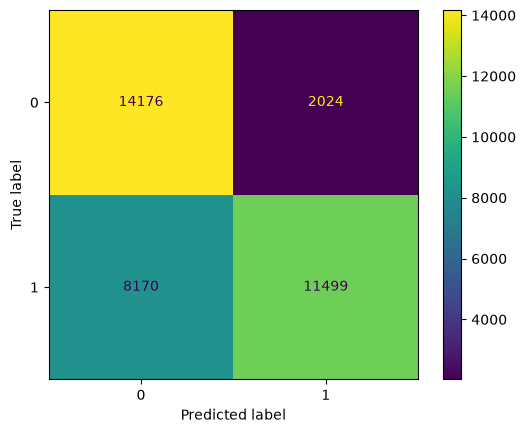

                     mean  count
tier                            
Lower (<0.50)       0.366  22346
High (0.50-0.80)    0.745   6047
Very high (>=0.80)  0.936   7476 

top 10% riskiest: 1.000 late, captures 18.2% of late orders
top 20% riskiest: 0.940 late, captures 34.3% of late orders
top 30% riskiest: 0.892 late, captures 48.8% of late orders
                orders  late_rate  flagged  missed_late
Shipping Mode                                          
First Class       5585      0.953    1.000            0
Same Day          1970      0.428    0.450            0
Second Class      7014      0.759    1.000            0
Standard Class   21300      0.384    0.002         8170


In [70]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, roc_auc_score, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)

proba = final_model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.50).astype(int)

mode_lr = Pipeline([("prep", mode_only), ("clf", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)

def row(y, p, pr):
    return {"accuracy": accuracy_score(y, p), "precision": precision_score(y, p),
            "recall": recall_score(y, p), "f1": f1_score(y, p), "roc_auc": roc_auc_score(y, pr)}

test_results = pd.DataFrame({
    "Majority baseline": row(y_test, np.ones(len(y_test), dtype=int), np.full(len(y_test), 0.5)),
    "Shipping Mode only (LR)": row(y_test, mode_lr.predict(X_test), mode_lr.predict_proba(X_test)[:, 1]),
    "Gradient boosting (final)": row(y_test, pred, proba),
}).T.round(3)
print(test_results, "\n")
print(classification_report(y_test, pred, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, pred)
plt.show()

tier = pd.cut(proba, bins=[0, 0.50, 0.80, 1.0001],
              labels=["Lower (<0.50)", "High (0.50-0.80)", "Very high (>=0.80)"], right=False)
print(pd.DataFrame({"tier": tier, "late": y_test.values})
      .groupby("tier", observed=True)["late"].agg(["mean", "count"]).round(3), "\n")
yy = y_test.values[np.argsort(-proba)]
for k in [0.10, 0.20, 0.30]:
    n = int(len(yy) * k)
    print(f"top {int(k*100)}% riskiest: {yy[:n].mean():.3f} late, captures {yy[:n].sum() / yy.sum():.1%} of late orders")

err = X_test.copy()
err["late"], err["pred"] = y_test.values, pred
err["missed"] = (err["late"] == 1) & (err["pred"] == 0)
print(err.groupby("Shipping Mode").agg(orders=("late", "size"), late_rate=("late", "mean"),
                                       flagged=("pred", "mean"), missed_late=("missed", "sum")).round(3))

In [52]:
import pandas as pd, numpy as np
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier

df = pd.read_csv("data/DataCoSupplyChainDataset.csv", encoding="latin-1")

df["order_dt"] = pd.to_datetime(df["order date (DateOrders)"])
df["order_month"] = df["order_dt"].dt.month
df["order_weekday"] = df["order_dt"].dt.day_of_week
df["order_hour"] = df["order_dt"].dt.hour

leak_cols = ["Days for shipping (real)", "Delivery Status", "Order Status", "shipping date (DateOrders)"]
id_pii_cols = ["Customer Email", "Customer Fname", "Customer Lname", "Customer Password",
               "Customer Street", "Customer Zipcode", "Customer Id", "Order Customer Id",
               "Order Item Id", "Order Item Cardprod Id", "Category Id", "Department Id",
               "Product Card Id", "Product Category Id"]
useless_cols = ["Product Description", "Order Zipcode", "Product Image", "Product Status"]
profit_cols = ["Benefit per order", "Order Profit Per Order", "Order Item Profit Ratio", "Sales per customer"]
redundant = ["Order Item Product Price", "Order Item Total"]
geo_cols = ["Order City", "Order State", "Customer City"]
dup_cols = ["Days for shipment (scheduled)"]

y = df["Late_delivery_risk"]
groups = df["Order Id"]
X = df.drop(columns=leak_cols + id_pii_cols + useless_cols + profit_cols + redundant + geo_cols + dup_cols
            + ["Late_delivery_risk", "Order Id", "order date (DateOrders)", "order_dt"])

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]

preprocess_trees = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                           min_frequency=100, sparse_output=False))]), cat_cols),
])
mode_only = ColumnTransformer([("cat", OneHotEncoder(), ["Shipping Mode"])])
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)

# final model = the best settings found by the tuning search
final_model = Pipeline([("prep", preprocess_trees),
                        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=100,
                                                               max_leaf_nodes=15, min_samples_leaf=20,
                                                               random_state=42))])
final_model.fit(X_train, y_train)

print(df.shape, X_train.shape, X_test.shape)

(180519, 57) (144650, 21) (35869, 21)


## Final evaluation (test set, evaluated once)
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Majority baseline | 0.548 | 0.548 | 1.000 | 0.708 | 0.500 |
| Shipping Mode only (LR) | 0.694 | 0.845 | 0.541 | 0.660 | 0.725 |
| Gradient boosting (final, cutoff 0.50) | 0.716 | 0.850 | 0.585 | 0.693 | 0.770 |

Test scores match cross-validation (ROC-AUC 0.770 vs 0.769), so the model generalizes. The majority baseline reaches recall 1.0 only by flagging every order (ROC-AUC 0.5), which is why recall is always read together with precision.

**Error analysis:** all 8,170 missed late orders are Standard Class (38% late, but flagged only 0.2% of the time). First Class and Second Class are flagged almost always (95% and 76% late). Same Day is the group where the model improves on a shipping-mode rule.

**Risk tiers (test):** lower 36.6% late, high 74.5% late, very high 93.6% late. The riskiest 10% of orders were 100% late.

## Business insight and recommendation
1. Shipping mode drives lateness. First Class (95% late) and Second Class (76% late) are late mostly because of the delivery times they promise. Average actual delivery was about 2.0 days for First Class (promised 1) and about 4 days for Second Class (promised 2), the same as Standard Class (hypothesis from averages).
2. Recommended action: warn customers and show a realistic delivery window for First and Second Class, and review whether those promises are achievable.
3. The model is a high-precision warning tool, not a complete predictor: it cannot see most late Standard Class orders.

## Limitations
- The data has no carrier, weather, distance or warehouse information, so about 37% of the lowest-risk tier is still late.
- The overall late rate (about 55%) is almost identical across markets, customer segments, months and weekdays, and the labels could not be verified against source records. Conclusions apply to this dataset and may not transfer to another company.
- `Late_delivery_risk` is derived from after-the-fact information (actual vs. scheduled days) and labels canceled shipments as not late. Cancellation cannot be known at order time, so these rows are label noise.
- The cost ratio for the cutoff is a business assumption, not something measured in the data.


In [71]:
import joblib, os

def top(s): return s.mode().iloc[0]

products = X_train.groupby("Product Name").agg(**{
    "Category Name": ("Category Name", top), "Department Name": ("Department Name", top),
    "Product Price": ("Product Price", "median"), "Sales": ("Sales", "median")})
countries = X_train.groupby("Order Country").agg(**{
    "Order Region": ("Order Region", top), "Market": ("Market", top)})

defaults = {c: (X_train[c].median() if c in num_cols else top(X_train[c])) for c in X_train.columns}

bundle = {"model": final_model, "columns": list(X_train.columns), "defaults": defaults,
          "products": products, "countries": countries,
          "options": {c: sorted(X_train[c].unique()) for c in ["Shipping Mode", "Type", "Customer Segment"]}}
joblib.dump(bundle, "model.joblib", compress=3)
print("model.joblib size (MB):", round(os.path.getsize("model.joblib") / 1e6, 1))

model.joblib size (MB): 0.1
